# Learning a switching linear dynamical system with Laplace variational EM

A switching linear dynamical system (SLDS) has a discrete state $z_t \in \{1, \ldots, K\}$ that selects which of $K$ linear
dynamical systems drives a continuous state $x_t \in \mathbb{R}^D$, which is observed through linear Gaussian emissions
$y_t \in \mathbb{R}^N$:

\begin{align*}
z_t \mid z_{t-1} &\sim \mathrm{Cat}(P[z_{t-1}, :]) \\
x_t \mid x_{t-1}, z_t = k &\sim \mathcal{N}(F_k x_{t-1} + b_k, Q_k) \\
y_t \mid x_t &\sim \mathcal{N}(H x_t + d, R).
\end{align*}

Exact inference is intractable (the posterior over $x$ is a mixture of $K^T$ Gaussians), so `GaussianSLDS` fits the
structured mean-field posterior $q(z)\, q(x)$ of *Laplace variational EM* (Zoltowski, Pillow and Linderman, 2020):
$q(z)$ is a Markov chain updated with the HMM smoother and $q(x)$ is a Gaussian with block-tridiagonal precision
found by Newton's method. The parameters are updated by closed-form M-steps on the expected sufficient statistics.

This notebook simulates data from a known SLDS, initializes a model with PCA and an autoregressive HMM, fits it,
and compares the inferred states and dynamics with the truth. The algorithm and its defaults follow
[`lindermanlab/ssm`](https://github.com/lindermanlab/ssm).

## Setup

In [1]:
%%capture
try:
    import dynamax
except ModuleNotFoundError:
    print('installing dynamax')
    %pip install -q dynamax[notebooks]
    import dynamax

In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
from matplotlib import pyplot as plt

from dynamax.slds import GaussianSLDS
from dynamax.utils.utils import find_permutation

## Data

Simulate $T = 1000$ steps from an SLDS with $K = 3$ states, a 2-dimensional continuous state and 10-dimensional emissions.
Each state rotates the continuous state by a different angle around a different center, so the states are
identifiable from the data.

In [3]:
num_states, state_dim, emission_dim, num_timesteps = 3, 2, 10, 1000
true_model = GaussianSLDS(num_states, state_dim, emission_dim)
true_params, _ = true_model.initialize(jr.PRNGKey(0))

rotation = lambda angle: 0.95 * jnp.array([[jnp.cos(angle), -jnp.sin(angle)], [jnp.sin(angle), jnp.cos(angle)]])
true_params = true_params._replace(
    transitions=true_params.transitions._replace(transition_matrix=0.9 * jnp.eye(num_states) + 0.1 / num_states),
    dynamics=true_params.dynamics._replace(
        weights=jnp.stack([rotation((k + 1) * jnp.pi / 20) for k in range(num_states)]),
        biases=jnp.array([[1.0, 0.0], [-0.5, 0.8], [-0.5, -0.8]]),
        covs=jnp.tile(0.1 * jnp.eye(state_dim), (num_states, 1, 1))),
    emissions=true_params.emissions._replace(covs=0.1 * jnp.ones((1, emission_dim))))

true_states, true_latents, emissions = true_model.sample(true_params, jr.PRNGKey(1), num_timesteps)

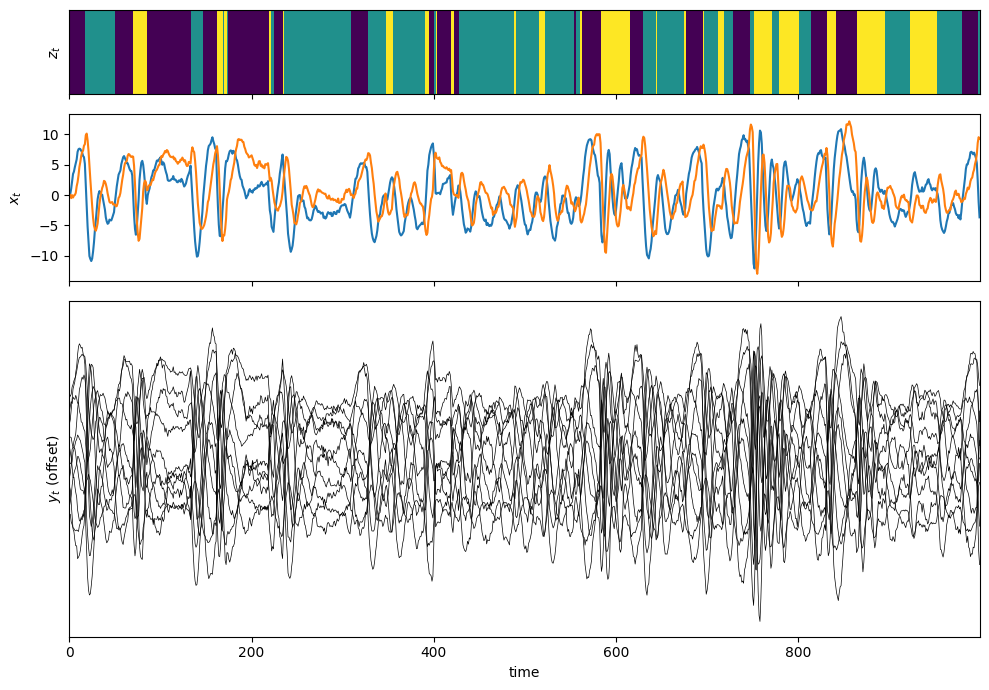

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw=dict(height_ratios=[1, 2, 4]))
axes[0].imshow(true_states[None], aspect="auto", cmap="viridis", interpolation="none")
axes[0].set_yticks([]); axes[0].set_ylabel("$z_t$")
axes[1].plot(true_latents); axes[1].set_ylabel("$x_t$")
axes[2].plot(emissions + 3 * jnp.arange(emission_dim), color="k", lw=0.5)
axes[2].set_ylabel("$y_t$ (offset)"); axes[2].set_xlabel("time"); axes[2].set_yticks([])
plt.tight_layout()

## Initialization and fitting

`initialize(method="pca_arhmm")` follows `ssm`: PCA of the emissions gives $H$, $d$, $R$ and a point estimate
$\hat x$ of the continuous states; an autoregressive HMM fitted to $\hat x$ by EM gives $\pi_0$, $P$ and the
dynamics $(F_k, b_k, Q_k)$.

`fit_em` then alternates variational E-steps (one coordinate-ascent sweep over $q(z)$ and $q(x)$ per iteration,
warm-started from the previous iteration) with M-steps. The returned objective is the log prior plus the evidence lower
bound (ELBO) before each M-step, and it increases monotonically (up to float32 rounding) when the damping of the parameter updates is off
(`damping=0`); the default `damping=0.5` mixes each update with the previous parameters, as `ssm` does.

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:04&lt;00:00]</div>

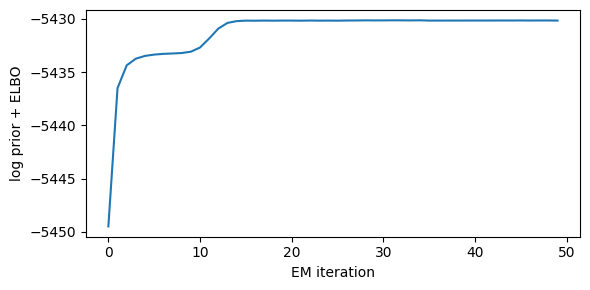

In [5]:
model = GaussianSLDS(num_states, state_dim, emission_dim)
params, props = model.initialize(jr.PRNGKey(2), method="pca_arhmm", emissions=emissions)
fitted_params, log_probs, posterior = model.fit_em(params, props, emissions, num_iters=50, return_posterior=True)

plt.figure(figsize=(6, 3))
plt.plot(log_probs)
plt.xlabel("EM iteration"); plt.ylabel("log prior + ELBO")
plt.tight_layout()

## Inferred states

`fit_em` returned the variational posterior of the last iteration (with a leading batch axis, one sequence here).
`most_likely_states` runs Viterbi on the discrete chain with $x$ fixed at its posterior mean. The state labels are
arbitrary, so we align them with the truth by `find_permutation`.

discrete state accuracy: 0.994


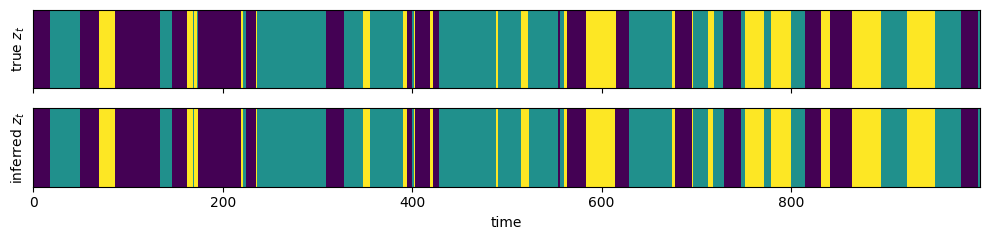

In [6]:
posterior = jax.tree_util.tree_map(lambda a: a[0], posterior)
inferred_states = model.most_likely_states(fitted_params, emissions, posterior)
permutation = find_permutation(inferred_states, true_states)
inferred_states = permutation[inferred_states]
print(f"discrete state accuracy: {jnp.mean(inferred_states == true_states):.3f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 2.5), sharex=True)
for ax, states, title in zip(axes, [true_states, inferred_states], ["true $z_t$", "inferred $z_t$"]):
    ax.imshow(states[None], aspect="auto", cmap="viridis", interpolation="none", vmin=0, vmax=num_states - 1)
    ax.set_yticks([]); ax.set_ylabel(title)
axes[1].set_xlabel("time")
plt.tight_layout()

The continuous state is identified only up to an invertible linear map (any $x \to G x + g$ can be absorbed into the
parameters), so we align the posterior mean with the true latents by least squares before plotting.

R^2 of the aligned posterior mean: 1.000


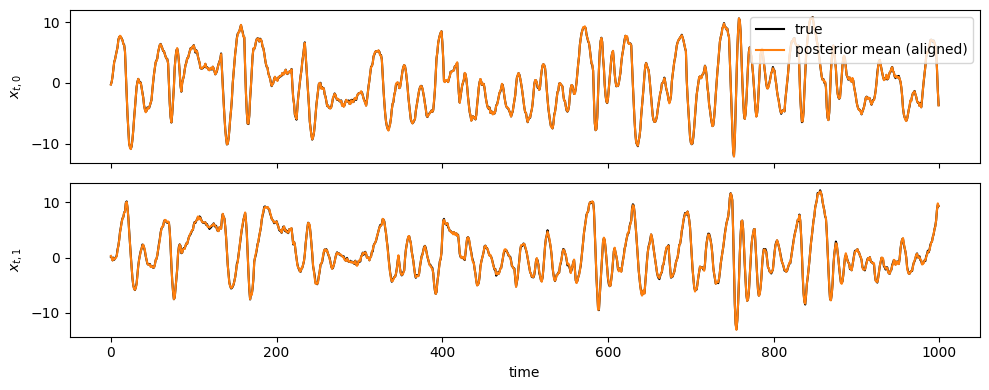

In [7]:
posterior_means = posterior.continuous.smoothed_means
design = jnp.concatenate([posterior_means, jnp.ones((num_timesteps, 1))], axis=1)
aligned_means = design @ jnp.linalg.lstsq(design, true_latents)[0]
r2 = 1 - jnp.sum((aligned_means - true_latents) ** 2) / jnp.sum((true_latents - true_latents.mean(0)) ** 2)
print(f"R^2 of the aligned posterior mean: {r2:.3f}")

fig, axes = plt.subplots(state_dim, 1, figsize=(10, 4), sharex=True)
for d, ax in enumerate(axes):
    ax.plot(true_latents[:, d], color="k", label="true")
    ax.plot(aligned_means[:, d], color="C1", label="posterior mean (aligned)")
    ax.set_ylabel(f"$x_{{t,{d}}}$")
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("time")
plt.tight_layout()

## Learned dynamics

The eigenvalues of each $F_k$ are invariant to the change of basis of the latent space, so they can be compared
directly with the truth: the rotation angles $9^\circ, 18^\circ, 27^\circ$ and the modulus $0.95$.

In [8]:
for k in range(num_states):
    eigenvalues = jnp.linalg.eigvals(fitted_params.dynamics.weights[jnp.argmax(permutation == k)])
    true_eigenvalues = jnp.linalg.eigvals(true_params.dynamics.weights[k])
    print(f"state {k}: |lambda| = {jnp.abs(eigenvalues[0]):.3f} (true {jnp.abs(true_eigenvalues[0]):.3f}), "
          f"angle = {jnp.rad2deg(jnp.abs(jnp.angle(eigenvalues[0]))):.1f} deg (true {jnp.rad2deg(jnp.abs(jnp.angle(true_eigenvalues[0]))):.1f} deg)")

state 0: |lambda| = 0.947 (true 0.950), angle = 9.0 deg (true 9.0 deg)
state 1: |lambda| = 0.947 (true 0.950), angle = 17.7 deg (true 18.0 deg)
state 2: |lambda| = 0.944 (true 0.950), angle = 27.0 deg (true 27.0 deg)


## Smoothed emissions and posterior samples

`smooth` returns the posterior-expected emissions $\sum_k q(z_t = k)\,(H_k \mathbb{E}[x_t] + d_k)$, and
`sample_posterior` draws joint samples of $(z, x)$ from $q(z)\,q(x)$.

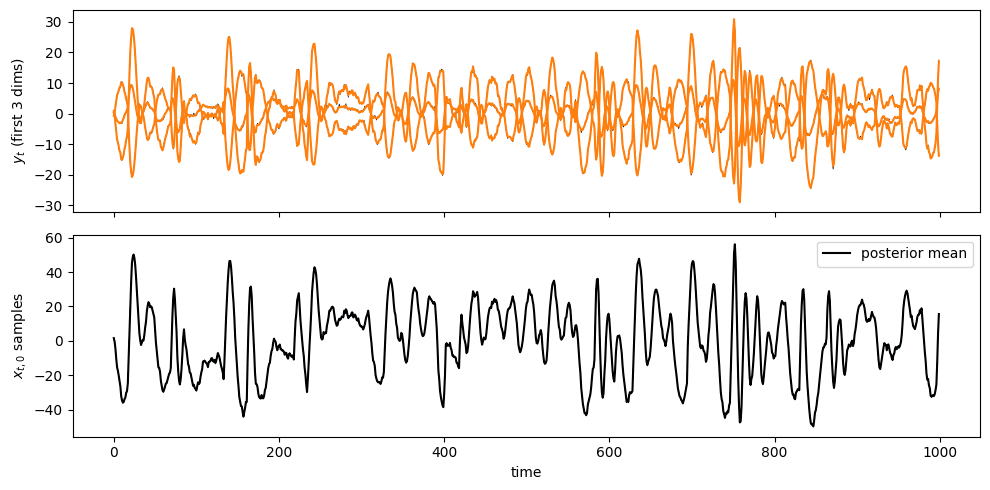

In [9]:
smoothed_emissions = model.smooth(fitted_params, posterior)
sampled_states, sampled_latents = model.sample_posterior(jr.PRNGKey(3), fitted_params, posterior, num_samples=20)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(emissions[:, :3], color="k", lw=0.5, label="data")
axes[0].plot(smoothed_emissions[:, :3], color="C1", lw=1.5)
axes[0].set_ylabel("$y_t$ (first 3 dims)")
for sample in sampled_latents:
    axes[1].plot(sample[:, 0], color="C0", lw=0.3, alpha=0.5)
axes[1].plot(posterior_means[:, 0], color="k", lw=1.5, label="posterior mean")
axes[1].set_ylabel("$x_{t,0}$ samples"); axes[1].set_xlabel("time"); axes[1].legend(loc="upper right")
plt.tight_layout()